# Zomato Data Analysis

In [113]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [23]:
df=pd.read_csv("zomato_data.csv")
df.head(10)

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
5,Timepass Dinner,Yes,No,3.8/5,286,600,Buffet
6,Rosewood International Hotel - Bar & Restaurant,No,No,3.6/5,8,800,Buffet
7,Onesta,Yes,Yes,4.6/5,2556,600,Cafes
8,Penthouse Cafe,Yes,No,4.0/5,324,700,other
9,Smacznego,Yes,No,4.2/5,504,550,Cafes


In [19]:
# NAN is not present
df.isna().sum()

name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

In [21]:
#no Duplicate data present
print(df.duplicated().sum())

0


### Convert the date type of column -rate

In [46]:
df['rate']=df['rate'].str.split('/').str[0]
df['rate']=df['rate'].astype(float)


In [47]:
#df["votes"].describe()['max']
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


### -> What type of restaurant do the majority of customers order from ?

Text(0.5, 0, 'Type of restaurant')

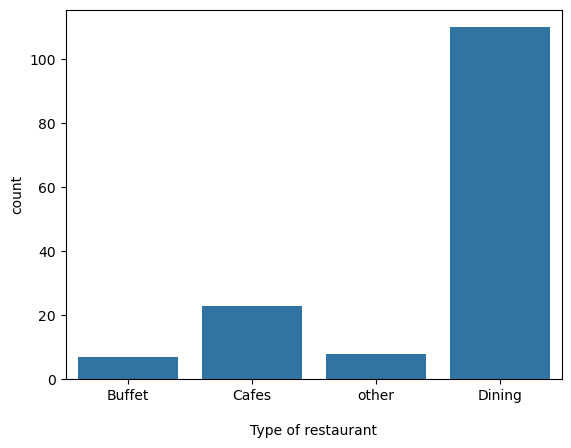

In [112]:
sns.countplot(x='listed_in(type)',data=df)
plt.xlabel('Type of restaurant',labelpad=15)


## -> How many votes has each type of restaurant received from customers ?

Text(0.5, 1.0, 'Total votes Received by Each Restaurant Type')

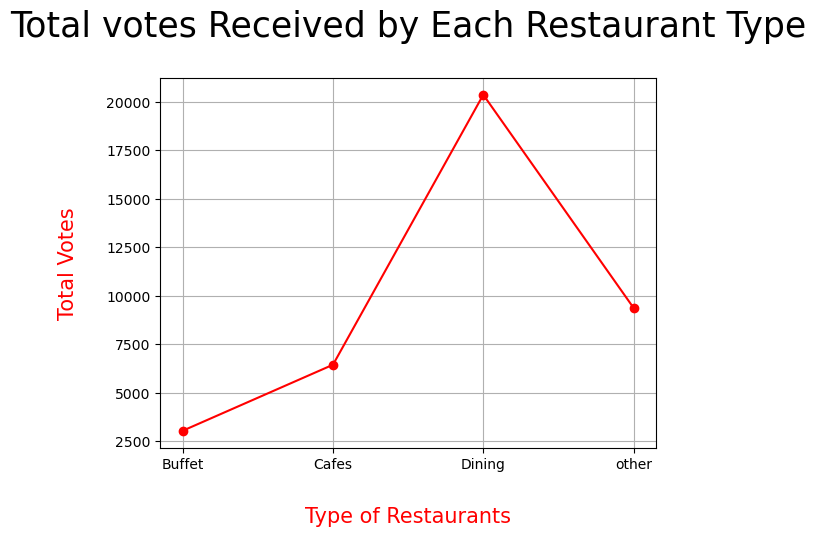

In [80]:
group_data=df.groupby(df['listed_in(type)'])['votes'].sum()
plt.plot(group_data.index,group_data.values,color='r',marker='o')
plt.grid(True)
plt.xlabel("Type of Restaurants",labelpad=25,color='red',size=15)
plt.ylabel("Total Votes",labelpad=20,color='red',size=15)
plt.title("Total votes Received by Each Restaurant Type",size=25
         ,pad=30)

## -> What are the ratings that the majority of the restaurants have received ?

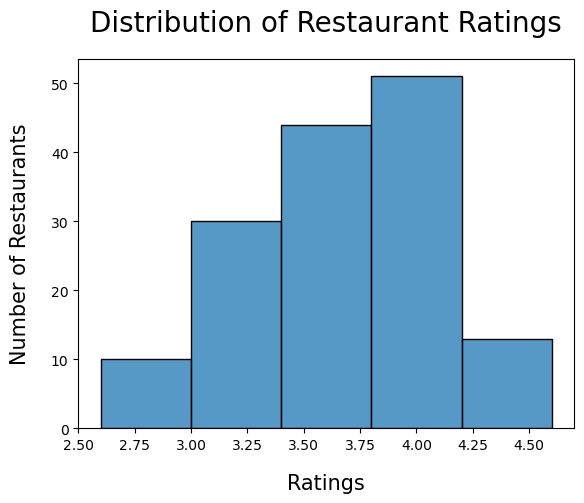

In [91]:
sns.histplot(df['rate'],bins=5)
plt.xlabel('Ratings',labelpad=15,size=15)
plt.ylabel("Number of Restaurants",labelpad=15,size=15)
plt.title("Distribution of Restaurant Ratings",size=20,pad=20)
plt.show()

## -> Zomato has observed that most couples order most of their food online. What is their average spending on each order ?

In [110]:
avg_cost=df.groupby('online_order')['approx_cost(for two people)'].mean()
print(f"average spent in online order is : {avg_cost.iloc[0]} and average spend in offline order is : {avg_cost.iloc[1]}")

average spent in online order is : 358.8888888888889 and average spend in offline order is : 510.3448275862069


Text(0.5, 1.0, 'Average Spending for online and offline orders')

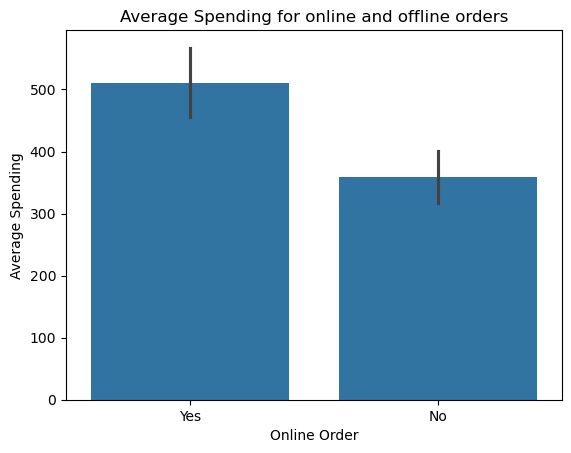

In [106]:
sns.barplot(data=df,x='online_order',y='approx_cost(for two people)')
plt.xlabel("Online Order")
plt.ylabel("Average Spending")
plt.title("Average Spending for online and offline orders")

## -> Which mode (online or offline ) has received the maximum rating ?

Text(0.5, 1.0, 'Average rating by online and offline mode')

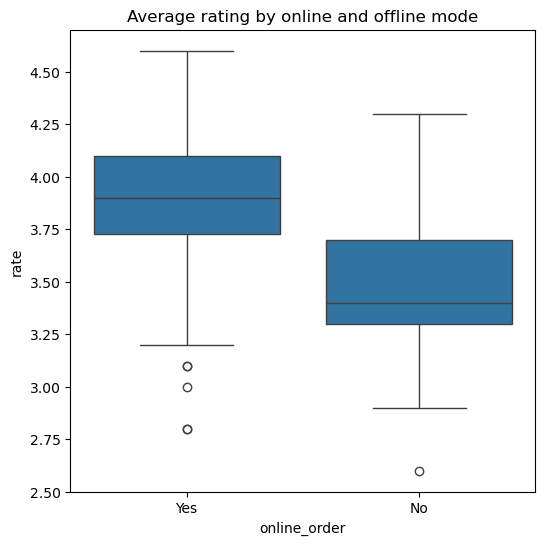

In [126]:
plt.figure(figsize=(6,6))
sns.boxplot(x='online_order',y='rate',data=df)
plt.title("Average rating by online and offline mode")


In [114]:
df.head()

,name,online_order,book_table,rate,votes,approx_cost(for two people),listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


## -> Which type of restaurant received more offline orders , so that Zomato can provide customers with some good offers ?

In [128]:
pivot_table = df.pivot_table(
    index="listed_in(type)",
    columns="online_order",
    aggfunc="size",
    fill_value=0
)

print(pivot_table)

online_order     No  Yes
listed_in(type)         
Buffet            3    4
Cafes             8   15
Dining           77   33
other             2    6


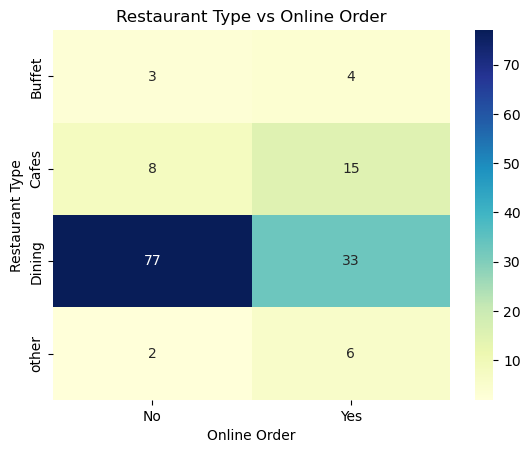

In [129]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.heatmap(pivot_table, annot=True, cmap="YlGnBu")

plt.title("Restaurant Type vs Online Order")
plt.xlabel("Online Order")
plt.ylabel("Restaurant Type")

plt.show()